# R-GCN on the team's entity graph

**Abdullah Balilah (new member 2: R-GCN)** · Team plan: *graph models with and without the V columns*

The team compares four graph models (GraphSAGE, GAT, R-GCN, HAN) with the same data, split, graph and training rules,
so that only the graph layer differs. **R-GCN** keeps a separate weight matrix for every type of link
(card–address, card–email, device–email, ...).

My tasks from the plan:
1. load the shared split file and check the graph (14,239 nodes, 12,401,340 links before repeats are removed),
2. build R-GCN with the mandatory settings,
3. train 3 seeds on the real graph and 3 seeds on the shuffled graph (6 runs),
4. save the logit scores and history of every run.

R-GCN uses **no payment columns**: a payment is scored only from its 6 entity nodes. Combining it with the tabular
models (late fusion) is done later by the evaluation member.

In [ ]:
import json
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score, roc_auc_score

QUICK = False   # True = 2 epochs and 1 seed, only to test that the notebook runs

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none")

GPU: Tesla T4


## 1. Load the shared split file

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/fraud_detection_project")
OUT = PROJECT / "results" / "rgcn"
OUT.mkdir(parents=True, exist_ok=True)

ENTITY_COLS = ["card1", "addr1", "P_emaildomain", "R_emaildomain", "DeviceInfo", "DeviceType"]
df = pd.read_parquet(PROJECT / "data" / "ieee_sorted_split.parquet",
                     columns=["TransactionID", "isFraud", "TransactionDT", "split"] + ENTITY_COLS)
df.groupby("split", sort=False).agg(payments=("isFraud", "size"), fraud_rate=("isFraud", "mean")).round(4)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,payments,fraud_rate
split,,
train,413378,0.0352
val,88581,0.0343
test,88581,0.0348


## 2. Build the entity graph (plan rules)

- Every entity column is a node type. Its nodes are the values seen in **training payments**, plus one *missing* node
  and one *unknown* node (for values that never appear in training).
- Two entities are linked if they appear in the same training payment. Each link is kept once.
- Validation and test payments are never used to build the graph.

The SOA member's official graph files were not available yet, so the graph is rebuilt here with exactly the same
rules. The two numbers the plan gives as a check must match before training.

In [ ]:
train_df = df[df["split"] == "train"]

# node numbers: for each column, its training values, then "missing", then "unknown"
node_index, offset, node_type = {}, 0, []
for t, col in enumerate(ENTITY_COLS):
    values = sorted(train_df[col].dropna().astype(str).unique())
    node_index[col] = {"values": {v: offset + i for i, v in enumerate(values)},
                       "missing": offset + len(values), "unknown": offset + len(values) + 1}
    node_type += [t] * (len(values) + 2)
    offset += len(values) + 2
N_NODES = offset
node_type = np.array(node_type)

def payment_nodes(part):
    out = np.empty((len(part), len(ENTITY_COLS)), np.int64)
    for j, col in enumerate(ENTITY_COLS):
        mapped = part[col].astype(str).map(node_index[col]["values"])
        out[:, j] = np.where(part[col].isna(), node_index[col]["missing"],
                             np.where(mapped.isna(), node_index[col]["unknown"], mapped))
    return out

nodes = {s: payment_nodes(df[df["split"] == s]) for s in ("train", "val", "test")}
labels = {s: df.loc[df["split"] == s, "isFraud"].to_numpy(np.float32) for s in ("train", "val", "test")}
ids = {s: df.loc[df["split"] == s, "TransactionID"].to_numpy() for s in ("train", "val", "test")}

def build_links(train_nodes):
    # link every pair of the 6 entities of each training payment; keep every link once
    parts = []
    for i, j in combinations(range(len(ENTITY_COLS)), 2):
        key = np.unique(train_nodes[:, i] * N_NODES + train_nodes[:, j])
        parts.append(np.stack([key // N_NODES, key % N_NODES], axis=1))
    return np.concatenate(parts)

links = build_links(nodes["train"])
pairs = len(list(combinations(range(len(ENTITY_COLS)), 2)))
check = pd.DataFrame({"plan": [14_239, 12_401_340],
                      "ours": [N_NODES, len(nodes["train"]) * pairs * 2]},
                     index=["nodes", "links before repeats are removed"])
check["match"] = check["plan"] == check["ours"]
print("links after repeats are removed:", f"{len(links):,}")
check

links after repeats are removed: 168,118


,plan,ours,match
nodes,14239,14239,True
links before repeats are removed,12401340,12401340,True


In [ ]:
# nodes per entity type, and how often a payment's entity is missing or unseen in training
rows = []
for j, col in enumerate(ENTITY_COLS):
    rows.append({"entity": col, "nodes": int((node_type == j).sum()),
                 "missing % (test)": round(100 * (nodes["test"][:, j] == node_index[col]["missing"]).mean(), 1),
                 "unseen % (test)": round(100 * (nodes["test"][:, j] == node_index[col]["unknown"]).mean(), 1)})
pd.DataFrame(rows)

,entity,nodes,missing % (test),unseen % (test)
0,card1,12244,0.0,1.4
1,addr1,320,10.5,0.0
2,P_emaildomain,61,18.1,0.0
3,R_emaildomain,62,79.1,0.0
4,DeviceInfo,1548,83.0,0.6
5,DeviceType,4,79.5,0.0


**Shuffled graph (control).** For each entity column the training payments' values are shuffled at random, then the
links are rebuilt. Every entity keeps how often it is used, but which entities are linked becomes random. The
payments themselves keep their real entities. Seeds 42, 1 and 2, as in the plan.

In [ ]:
def shuffled_links(seed):
    rng = np.random.default_rng(seed)
    shuffled = np.stack([rng.permutation(nodes["train"][:, j]) for j in range(len(ENTITY_COLS))], axis=1)
    return build_links(shuffled)

real_set = set((links[:, 0] * N_NODES + links[:, 1]).tolist())
for seed in (42, 1, 2):
    sl = shuffled_links(seed)
    same = len(real_set & set((sl[:, 0] * N_NODES + sl[:, 1]).tolist()))
    print(f"shuffled seed {seed}: {len(sl):,} links, {100 * same / len(sl):.1f}% of them also in the real graph")

shuffled seed 42: 281,673 links, 34.5% of them also in the real graph
shuffled seed 1: 281,833 links, 34.5% of them also in the real graph
shuffled seed 2: 281,690 links, 34.6% of them also in the real graph


## 3. R-GCN

One R-GCN layer updates node *v* as

$$h_v' = W_0 h_v + \sum_r \frac{1}{c_{v,r}} \sum_{u \in N_r(v)} W_r h_u$$

with one weight matrix $W_r$ per link type $r$ and $c_{v,r}$ = number of neighbours of $v$ of that link type.
A link type is (entity type of the sender → entity type of the receiver), so with 6 entity types there are 30 link
types. Each link is used in both directions.

| Setting | Value | Source |
| --- | --- | --- |
| Node input | learned node embedding + entity-type embedding, size 64 | plan |
| Layers | 2 R-GCN layers (ReLU between) | plan |
| Payment score | 6 entity embeddings joined (384) → Linear(384,128) → ReLU → dropout → Linear(128,1) | plan |
| Unknown-node training | in training, 10 % of entities are replaced by their *unknown* node | plan |
| Loss, optimizer | weighted BCE, fraud weight √(N0/N1); Adam | plan |
| Epochs | 12, keep the epoch with the best validation ROC-AUC | plan |
| Learning rate, dropout | 0.001, 0.2 | my choice (fixed for all runs) |
| Weight sharing | none: a full 64×64 matrix for every link type | my choice |

In [ ]:
def relation_matrix(links):
    # one sparse (N, R*N) matrix: row = receiving node, column block = link type
    src = np.concatenate([links[:, 0], links[:, 1]])
    dst = np.concatenate([links[:, 1], links[:, 0]])
    pair = node_type[src] * len(ENTITY_COLS) + node_type[dst]
    pair_ids, rel = np.unique(pair, return_inverse=True)
    _, inv, count = np.unique(dst * len(pair_ids) + rel, return_inverse=True, return_counts=True)
    weight = 1.0 / count[inv]                                   # 1 / c_{v,r}
    index = torch.as_tensor(np.stack([dst, rel * N_NODES + src]))
    adj = torch.sparse_coo_tensor(index, torch.as_tensor(weight, dtype=torch.float32), (N_NODES, len(pair_ids) * N_NODES))
    names = [f"{ENTITY_COLS[p // len(ENTITY_COLS)]} -> {ENTITY_COLS[p % len(ENTITY_COLS)]}" for p in pair_ids]
    return adj.coalesce(), names


class RGCNLayer(nn.Module):
    def __init__(self, dim, n_rel):
        super().__init__()
        self.self_loop = nn.Linear(dim, dim)
        self.weight = nn.Parameter(torch.empty(n_rel, dim, dim))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, h, adj):
        messages = torch.einsum("nd,rde->rne", h, self.weight).reshape(-1, h.size(1))   # W_r h_u for every r
        return self.self_loop(h) + torch.sparse.mm(adj, messages)


class RGCNFraud(nn.Module):
    def __init__(self, n_rel, dim=64, dropout=0.2):
        super().__init__()
        self.node_emb = nn.Embedding(N_NODES, dim)
        self.type_emb = nn.Embedding(len(ENTITY_COLS), dim)
        self.register_buffer("node_type", torch.as_tensor(node_type))
        self.layers = nn.ModuleList([RGCNLayer(dim, n_rel), RGCNLayer(dim, n_rel)])
        self.head = nn.Sequential(nn.Linear(6 * dim, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, 1))

    def node_embeddings(self, adj):
        h = self.node_emb.weight + self.type_emb(self.node_type)
        h = torch.relu(self.layers[0](h, adj))
        return self.layers[1](h, adj)

    def forward(self, adj, payment_nodes):
        h = self.node_embeddings(adj)
        return self.head(h[payment_nodes].flatten(1)).squeeze(-1)


adj, link_types = relation_matrix(links)
print(len(link_types), "link types;", sum(p.numel() for p in RGCNFraud(len(link_types)).parameters()), "parameters")

30 link types; 1215169 parameters


## 4. Training

In [ ]:
UNKNOWN = torch.tensor([node_index[c]["unknown"] for c in ENTITY_COLS], device=DEVICE)
POS_WEIGHT = float(np.sqrt((labels["train"] == 0).sum() / (labels["train"] == 1).sum()))

@torch.no_grad()
def predict(model, adj, payment_nodes):
    model.eval()
    h = model.node_embeddings(adj)
    return torch.cat([model.head(h[payment_nodes[i:i + 65536]].flatten(1)).squeeze(-1)
                      for i in range(0, len(payment_nodes), 65536)]).cpu().numpy()


def train_run(name, run_links, seed, epochs=12, lr=1e-3, batch=4096):
    torch.manual_seed(seed)
    np.random.seed(seed)
    start = time.time()
    adj, names = relation_matrix(run_links)
    adj = adj.to(DEVICE)
    model = RGCNFraud(len(names)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))
    x = {s: torch.as_tensor(nodes[s], device=DEVICE) for s in nodes}
    y_train = torch.as_tensor(labels["train"], device=DEVICE)

    history, best_roc, best_epoch, best_state = [], -1, 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(y_train), device=DEVICE)
        total = 0.0
        for i in range(0, len(perm), batch):
            r = perm[i:i + batch]
            batch_nodes = x["train"][r]
            hide = torch.rand(batch_nodes.shape, device=DEVICE) < 0.10              # unknown-node training
            batch_nodes = torch.where(hide, UNKNOWN.expand_as(batch_nodes), batch_nodes)
            loss = loss_fn(model(adj, batch_nodes), y_train[r])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(r)
        val_score = predict(model, adj, x["val"])
        val_roc = roc_auc_score(labels["val"], val_score)
        history.append({"epoch": epoch, "loss": total / len(perm), "val_roc_auc": val_roc,
                        "val_pr_auc": average_precision_score(labels["val"], val_score)})
        if val_roc > best_roc:
            best_roc, best_epoch = val_roc, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    scores = {s: predict(model, adj, x[s]) for s in ("val", "test")}   # test is scored only here
    for s, score in scores.items():
        pd.DataFrame({"TransactionID": ids[s], "isFraud": labels[s], "score": score}).to_parquet(OUT / f"{name}_{s}.parquet", index=False)
    minutes = (time.time() - start) / 60
    info = {"model": "R-GCN", "run": name, "seed": seed, "chosen_epoch": best_epoch,
            "graph": "rebuilt with the plan's rules (14,239 nodes)", "shuffled": "shuf" in name,
            "settings": {"layers": 2, "dim": 64, "epochs": epochs, "lr": lr, "dropout": 0.2, "batch": batch,
                         "weight_sharing": "none", "unknown_rate": 0.10, "fraud_weight": POS_WEIGHT},
            "link_types": names, "epochs": history}
    (OUT / f"{name}_history.json").write_text(json.dumps(info, indent=1))
    result = {"run": name, "test_roc_auc": roc_auc_score(labels["test"], scores["test"]),
              "test_pr_auc": average_precision_score(labels["test"], scores["test"]),
              "best_epoch": best_epoch, "minutes": round(minutes, 1)}
    print(f"{name:18s} best epoch {best_epoch:2d} | test ROC-AUC {result['test_roc_auc']:.4f} "
          f"PR-AUC {result['test_pr_auc']:.4f} | {minutes:.1f} min")
    return result, history, model, adj

In [ ]:
SEEDS = [42] if QUICK else [42, 1, 2]
EPOCHS = 2 if QUICK else 12

results, histories = [], {}
for seed in SEEDS:
    r, h, m, a = train_run(f"rgcn_seed{seed}", links, seed, epochs=EPOCHS)
    results.append(r); histories[r["run"]] = h
    if seed == 42:
        model_real, adj_real = m, a
    r, h, _, _ = train_run(f"rgcn_shuf_seed{seed}", shuffled_links(seed), seed, epochs=EPOCHS)
    results.append(r); histories[r["run"]] = h

results = pd.DataFrame(results)
results.to_csv(OUT / "results_table.csv", index=False)

rgcn_seed42        best epoch  8 | test ROC-AUC 0.7609 PR-AUC 0.1562 | 1.0 min
rgcn_shuf_seed42   best epoch  8 | test ROC-AUC 0.7629 PR-AUC 0.1530 | 1.1 min
rgcn_seed1         best epoch 10 | test ROC-AUC 0.7488 PR-AUC 0.1467 | 1.0 min
rgcn_shuf_seed1    best epoch  8 | test ROC-AUC 0.7517 PR-AUC 0.1459 | 1.1 min
rgcn_seed2         best epoch  6 | test ROC-AUC 0.7601 PR-AUC 0.1332 | 1.0 min
rgcn_shuf_seed2    best epoch  8 | test ROC-AUC 0.7578 PR-AUC 0.1407 | 1.1 min


## 5. Results (test set)

In [ ]:
def mean_range(x):
    return f"{x.mean():.3f} ({x.min():.3f}-{x.max():.3f})"

results["graph"] = np.where(results["run"].str.contains("shuf"), "shuffled graph", "real graph")
summary = results.groupby("graph").agg(test_roc_auc=("test_roc_auc", mean_range), test_pr_auc=("test_pr_auc", mean_range),
                                       best_epoch=("best_epoch", "mean"), minutes=("minutes", "mean"))
summary

,test_roc_auc,test_pr_auc,best_epoch,minutes
graph,,,,
real graph,0.757 (0.749-0.761),0.145 (0.133-0.156),8.0,1.0
shuffled graph,0.757 (0.752-0.763),0.147 (0.141-0.153),8.0,1.1


In [ ]:
paired = results.assign(seed=results["run"].str.extract(r"seed(\d+)")[0]).pivot(index="seed", columns="graph",
                                                                                 values=["test_roc_auc", "test_pr_auc"])
paired[("test_roc_auc", "real - shuffled")] = paired[("test_roc_auc", "real graph")] - paired[("test_roc_auc", "shuffled graph")]
paired[("test_pr_auc", "real - shuffled")] = paired[("test_pr_auc", "real graph")] - paired[("test_pr_auc", "shuffled graph")]
paired.round(4)

test_roc_auc                test_pr_auc                   test_roc_auc  \
graph   real graph shuffled graph  real graph shuffled graph real - shuffled   
seed                                                                           
1           0.7488         0.7517      0.1467         0.1459         -0.0029   
2           0.7601         0.7578      0.1332         0.1407          0.0022   
42          0.7609         0.7629      0.1562         0.1530         -0.0020   

          test_pr_auc  
graph real - shuffled  
seed                   
1              0.0008  
2             -0.0075  
42             0.0031

In [ ]:
reference = pd.DataFrame([
    ("GraphSAGE alone, entities only, 1 seed (team)", 0.741, 0.138),
    ("Paper: TabNet-GraphSAGE hybrid (all columns)", 0.791, 0.206),
    ("Plain network, column set A, 3 seeds (team)", 0.841, 0.410),
], columns=["model", "test ROC-AUC", "test PR-AUC"])
for g in ("real graph", "shuffled graph"):
    part = results[results["graph"] == g]
    reference.loc[len(reference)] = [f"R-GCN, {g}, mean of seeds (this notebook)",
                                     round(part["test_roc_auc"].mean(), 3), round(part["test_pr_auc"].mean(), 3)]
reference

,model,test ROC-AUC,test PR-AUC
0,"GraphSAGE alone, entities only, 1 seed (team)",0.741,0.138
1,Paper: TabNet-GraphSAGE hybrid (all columns),0.791,0.206
2,"Plain network, column set A, 3 seeds (team)",0.841,0.410
3,"R-GCN, real graph, mean of seeds (this notebook)",0.757,0.145
4,"R-GCN, shuffled graph, mean of seeds (this not...",0.757,0.147


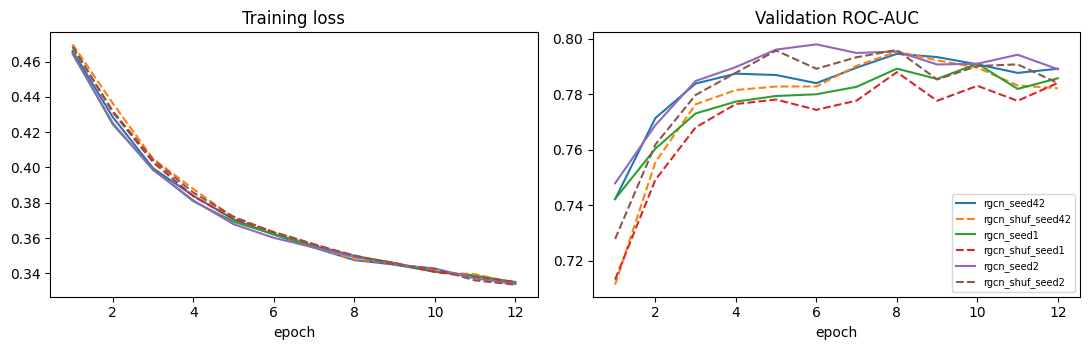

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, h in histories.items():
    h = pd.DataFrame(h)
    style = "--" if "shuf" in name else "-"
    ax[0].plot(h["epoch"], h["loss"], style, label=name)
    ax[1].plot(h["epoch"], h["val_roc_auc"], style, label=name)
ax[0].set(title="Training loss", xlabel="epoch")
ax[1].set(title="Validation ROC-AUC", xlabel="epoch")
ax[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "rgcn_curves.png", dpi=130)
plt.show()

## 6. Which link types does the model use?

For the seed-42 model on the real graph: switch off one link type at a time (no retraining) and measure how much the
**validation** ROC-AUC drops. A large drop means the model relies on that link type.

In [ ]:
full = roc_auc_score(labels["val"], predict(model_real, adj_real, torch.as_tensor(nodes["val"], device=DEVICE)))
index, values = adj_real.indices(), adj_real.values()
drops = []
for r, name in enumerate(link_types):
    keep = (index[1] // N_NODES) != r
    adj_r = torch.sparse_coo_tensor(index[:, keep], values[keep], adj_real.shape).coalesce()
    score = predict(model_real, adj_r, torch.as_tensor(nodes["val"], device=DEVICE))
    drops.append(full - roc_auc_score(labels["val"], score))
link_table = pd.DataFrame({"link type": link_types, "val ROC-AUC drop": drops}).sort_values("val ROC-AUC drop", ascending=False)
link_table.to_csv(OUT / "link_type_drop.csv", index=False)
print(f"validation ROC-AUC with all link types: {full:.4f}")
link_table.head(8).round(4)

validation ROC-AUC with all link types: 0.7945


,link type,val ROC-AUC drop
15,R_emaildomain -> card1,0.0064
20,DeviceInfo -> card1,0.0048
10,P_emaildomain -> card1,0.0036
24,DeviceInfo -> DeviceType,0.0028
25,DeviceType -> card1,0.0025
8,addr1 -> DeviceInfo,0.0011
4,card1 -> DeviceType,0.0010
18,R_emaildomain -> DeviceInfo,0.0004


## 7. Observations

1. **The graph matches the plan.** 14,239 nodes and 12,401,340 links before repeats are removed (168,118 after), so this graph follows the same rules as the SOA member's graph.
2. **Much of the entity information is missing.** In the test set, DeviceInfo is missing for 83.0% of payments, DeviceType for 79.5% and R_emaildomain for 79.1%. For most payments R-GCN therefore sees only card1, addr1 and P_emaildomain.
3. **R-GCN alone is weak but above GraphSAGE alone.** Real graph: test ROC-AUC 0.757 (0.749-0.761), PR-AUC 0.145 (0.133-0.156). The team's GraphSAGE alone scored 0.741 / 0.138 (1 seed). A model that only sees the payment's entities, with no payment columns, cannot reach the tabular models (plain network 0.841 / 0.410).
4. **The real links do not beat random links.** Shuffled graph: ROC-AUC 0.758 (0.752-0.763), PR-AUC 0.147 (0.141-0.153). Real minus shuffled per seed: ROC-AUC -0.002, -0.003, +0.002; PR-AUC +0.003, +0.001, -0.008. The differences are smaller than the spread between seeds, so the real links add nothing here (research question 3 of the plan).
5. **Why it still works without real links.** Each payment keeps its own real card, address, e-mail and device nodes, and each node has its own learned embedding. Most of the score comes from "which card / which e-mail domain", not from the neighbours.
6. **Link types.** Switching off one link type at a time lowers the validation ROC-AUC (0.7945) by at most 0.006 (R_emaildomain -> card1), then DeviceInfo -> card1 (0.005) and P_emaildomain -> card1 (0.004). No single link type matters much, which agrees with point 4.
7. **Training.** The best validation epoch was 6-10 out of 12; one run takes about 1 minute on a T4.

**Limits:** graph rebuilt with the plan's rules, not yet the SOA member's file; 3 seeds; learning rate and dropout fixed, not tuned; no bootstrap intervals here (the evaluation member computes them on the saved scores).